# Decision Tree Learning (C4.5)

Eksperimen DTL v3 dan v4, perbandingan dengan scikit-learn, dan pembuatan
ulang submission v4. Macro-F1 pada split 20% ini memakai random_state=824.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

REPO_ROOT = Path.cwd().parent if (Path.cwd().parent / "src").is_dir() else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from src.evaluation import generate_submission, save_and_verify_model
from src.models import C45DecisionTree, DEFAULT_DTL_CONFIGS
from src.preprocess.dtl_features import DTL_CATEGORICAL_COLUMNS, prepare_dtl_features

RANDOM_STATE = 824

In [2]:
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

dtl_data = train_df.drop_duplicates()
X_dtl = prepare_dtl_features(dtl_data)
X_dtl_v3 = prepare_dtl_features(dtl_data, indicators=False)
y_dtl = dtl_data["is_canceled"]
dtl_categorical_indices = [
    X_dtl.columns.get_loc(column) for column in DTL_CATEGORICAL_COLUMNS
]
dtl_numerical = [
    column for column in X_dtl if column not in DTL_CATEGORICAL_COLUMNS
]

X_dtl_train, X_dtl_val, y_dtl_train, y_dtl_val = train_test_split(
    X_dtl, y_dtl, test_size=0.2, stratify=y_dtl, random_state=RANDOM_STATE
)

## Model from scratch

V4 menambah indikator untuk beberapa nilai jumlah tamu, permintaan khusus,
dan malam menginap. Nilai kosong tetap kosong pada indikator.
Konfigurasi v4 memakai max_depth=16, min_branch_weight=7, dan threshold=0.48.

In [3]:
dtl_v3 = C45DecisionTree(
    categorical_features=dtl_categorical_indices, max_depth=15, min_branch_weight=6
).fit(X_dtl_v3.loc[X_dtl_train.index], y_dtl_train)
dtl_v3_prediction = dtl_v3.predict(X_dtl_v3.loc[X_dtl_val.index])

dtl_config = dict(
    DEFAULT_DTL_CONFIGS[0], categorical_features=dtl_categorical_indices
)
dtl_tree = C45DecisionTree(**dtl_config).fit(X_dtl_train, y_dtl_train)
dtl_val_prediction = dtl_tree.predict(X_dtl_val)
dtl_f1 = f1_score(y_dtl_val, dtl_val_prediction, average="macro")

## Pembanding scikit-learn

Imputasi dan encoding dipelajari dari bagian train. Pembanding memakai
criterion entropy dan ccp_alpha yang dipilih berdasarkan macro-F1 validasi.

In [4]:
sklearn_dtl_prep = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), dtl_numerical),
    ("categorical", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore"),
    ), DTL_CATEGORICAL_COLUMNS),
])
X_sklearn_train = sklearn_dtl_prep.fit_transform(X_dtl_train)
X_sklearn_val = sklearn_dtl_prep.transform(X_dtl_val)

sklearn_best_f1 = -1
for ccp_alpha in [0.0001, 0.0005, 0.001]:
    baseline = DecisionTreeClassifier(
        criterion="entropy",
        ccp_alpha=ccp_alpha,
        max_depth=dtl_config["max_depth"],
        random_state=RANDOM_STATE,
    ).fit(X_sklearn_train, y_dtl_train)
    predictions = baseline.predict(X_sklearn_val)
    macro_f1 = f1_score(y_dtl_val, predictions, average="macro")
    if macro_f1 > sklearn_best_f1:
        sklearn_best_f1 = macro_f1
        sklearn_best_alpha = ccp_alpha
        sklearn_val_prediction = predictions

print(f"ccp_alpha yang dipilih: {sklearn_best_alpha}")
dtl_comparison = pd.DataFrame([
    {
        "model": "C4.5 v3",
        "accuracy": accuracy_score(y_dtl_val, dtl_v3_prediction),
        "macro_f1": f1_score(y_dtl_val, dtl_v3_prediction, average="macro"),
    },
    {
        "model": "C4.5 v4",
        "accuracy": accuracy_score(y_dtl_val, dtl_val_prediction),
        "macro_f1": dtl_f1,
    },
    {
        "model": "scikit-learn",
        "accuracy": accuracy_score(y_dtl_val, sklearn_val_prediction),
        "macro_f1": sklearn_best_f1,
    },
])
dtl_comparison

ccp_alpha yang dipilih: 0.0005


,model,accuracy,macro_f1
0,C4.5 v3,0.857534,0.837438
1,C4.5 v4,0.857169,0.838420
2,scikit-learn,0.854247,0.831828


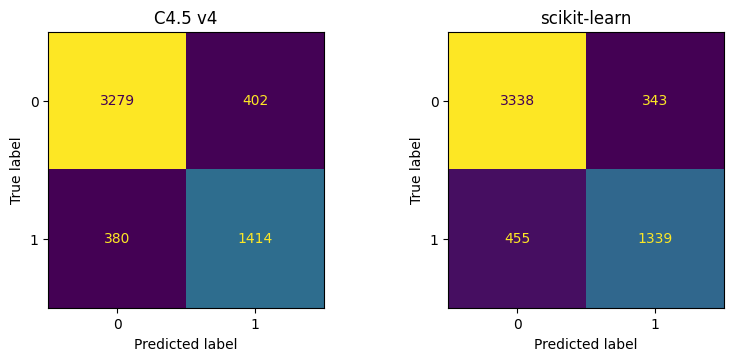

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout="constrained")
for ax, (name, predictions) in zip(axes, [
    ("C4.5 v4", dtl_val_prediction),
    ("scikit-learn", sklearn_val_prediction),
]):
    ConfusionMatrixDisplay.from_predictions(
        y_dtl_val, predictions, labels=[0, 1], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.show()

## Submission v4

Model dilatih ulang pada seluruh data train, disimpan, dan dimuat kembali
sebelum prediksi test. Threshold ikut tersimpan di dalam model.

In [6]:
X_dtl_test = prepare_dtl_features(test_df)
dtl_final = C45DecisionTree(**dtl_config).fit(X_dtl, y_dtl)
dtl_reloaded = save_and_verify_model(dtl_final, "output/dtl.pkl")
np.testing.assert_array_equal(
    dtl_final.predict(X_dtl_test), dtl_reloaded.predict(X_dtl_test)
)
dtl_submission = generate_submission(
    dtl_reloaded,
    X_dtl_test,
    test_df["id"],
    sample_submission,
    "output/submission_dtl_v4.csv",
    random_state=RANDOM_STATE,
)
pd.testing.assert_series_equal(dtl_submission["id"], sample_submission["id"])
dtl_submission.head()

Model berhasil disimpan ke 'output/dtl.pkl' (Ukuran: 165.12 KB)
Model berhasil di-load kembali dari 'output/dtl.pkl'!

Melakukan prediksi pada data test...


File submisi 'output/submission_dtl_v4.csv' berhasil dibuat dan siap dikumpulkan!

Distribusi hasil prediksi:
is_canceled
0    4709
1    2135
Name: count, dtype: int64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


## Visualisasi pohon C4.5

Gambar memakai model submisi v4. Atur `top_n` untuk membatasi jumlah cabang yang terlihat.

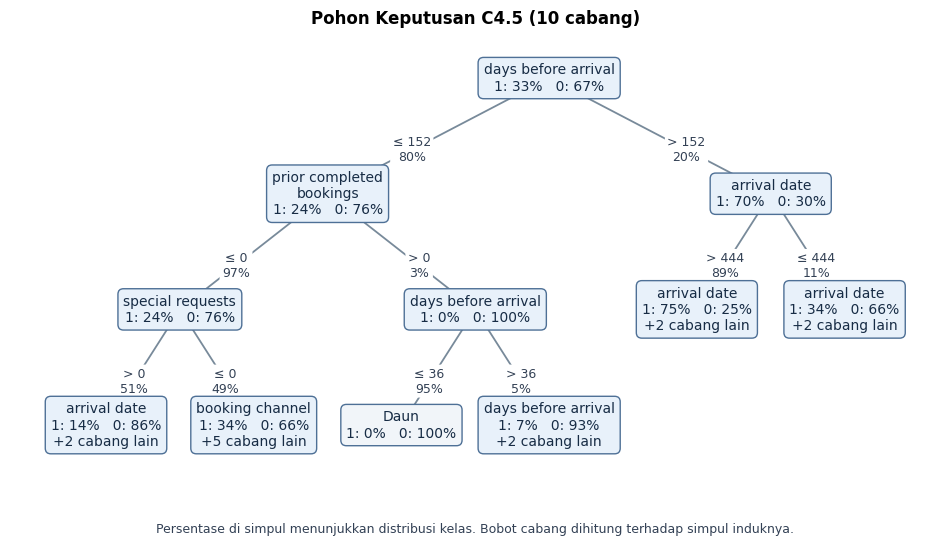

In [7]:
from src.models.dtl_visualization import plot_dtl_tree
from src.preprocess.dtl_features import CATEGORY_VALUES

top_n = 10
fig = plot_dtl_tree(dtl_final, X_dtl.columns, top_n, CATEGORY_VALUES)
fig.savefig(REPO_ROOT / "output/dtl_tree.png", dpi=220)
plt.show()